# Harmonogramowanie w zrobotyzowanej komórce: zadanie typu job-shop

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_4.ipynb)

W tym laboratorium planujemy pracę niewielkiej zautomatyzowanej komórki produkcyjnej. Przykład jest konkretny, a model odpowiada klasycznemu problemowi **harmonogramowania typu job-shop**.

Wybieramy czasy rozpoczęcia operacji tak, aby:

1. każdy zestaw przechodził przez wymaganą sekwencję stanowisk,
2. żadne stanowisko nie obsługiwało dwóch zestawów jednocześnie,
3. wszystkie zestawy były gotowe możliwie najwcześniej.

**Czas zakończenia wszystkich zadań** to *makespan*, zwykle oznaczany jako $C_{max}$.

## Pytania, które zbadamy

1. Jak zapisać opis komórki produkcyjnej jako zadania, stanowiska, operacje i czasy ich trwania?
2. Dlaczego potrzebujemy zmiennych binarnych, gdy dwie operacje konkurują o to samo stanowisko?
3. Jak zbudować niewielki mieszany model liniowy z całkowitoliczbowymi zmiennymi w PuLP?
4. Jak sprawdzić obliczony harmonogram przed zaufaniem wykresowi?
5. Jak odczytać produkcyjny wykres Gantta?

## Scenariusz: ostatnie minuty przed pokazem

Laboratorium robotyki przygotowuje cztery zestawy demonstracyjne przed przybyciem gości. Każdy zestaw musi odwiedzić trzy zautomatyzowane stanowiska, lecz kolejność zależy od zestawu.

Stanowiska mają w danych stałe angielskie nazwy:

- **Laser cutter** — wycinarka laserowa: wycina lub przycina części.
- **Robot arm** — ramię robota: montuje części.
- **Vision test** — kontrola wizyjna: sprawdza zestaw za pomocą kamery.

Nazwy zadań również pozostają kluczami danych: **Frame kit** to zestaw ramy, **Sensor mast** — maszt czujnika, **Gripper jaw** — szczęka chwytaka, a **Battery tray** — uchwyt akumulatora. Używaj tych samych kluczy przy odczycie tabel i zmianach danych.

Stanowisko może obsługiwać tylko jeden zestaw naraz. Zestaw może czekać między stanowiskami, ale nie może pominąć operacji ani zmienić własnej kolejności.

## Ilustracja komórki robotycznej

![Harmonogramowanie w zrobotyzowanej komórce](https://raw.githubusercontent.com/AdoHaha/automation_robotics_lab/refs/heads/master/job_illustration.png)

Ilustracja przedstawia współdzieloną komórkę: każdy zestaw ma ustaloną trasę, stanowiska obsługują po jednym zestawie, a oczekujące zestawy znajdują się w buforze.

In [1]:
%pip install pulp==3.3.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 11.7 MB/s  0:00:01
  Attempting uninstall: pulp
    Found existing installation: PuLP 4.2.0
    Uninstalling PuLP-4.2.0:
      Successfully uninstalled PuLP-4.2.0


In [2]:
# Sprawdź dostępność solvera również w nowej sesji Colab.
try:
    import pulp
except ModuleNotFoundError:
    %pip install "pulp>=3.3,<4" pandas matplotlib
    import pulp

if int(pulp.__version__.split(".")[0]) != 3:
    raise RuntimeError("Ten notebook wymaga PuLP 3.x. Uruchom pierwsza komorke instalacyjna i zrestartuj kernel.")

import pandas as pd

# Dane głównego ćwiczenia.
# Każde zadanie to trasa: (station, processing_time_in_minutes), czyli stanowisko i czas w minutach.
jobs = {
    "Frame kit": [
        ("Laser cutter", 3),
        ("Robot arm", 4),
        ("Vision test", 2),
    ],
    "Sensor mast": [
        ("Robot arm", 2),
        ("Laser cutter", 4),
        ("Vision test", 3),
    ],
    "Gripper jaw": [
        ("Laser cutter", 2),
        ("Vision test", 1),
        ("Robot arm", 3),
    ],
    "Battery tray": [
        ("Vision test", 2),
        ("Robot arm", 3),
        ("Laser cutter", 3),
    ],
}

# Zapisz krotki tras jako wiersze DataFrame, aby łatwo obejrzeć każdą operację.
operation_rows = []
for job, route in jobs.items():
    for operation, (station, duration) in enumerate(route, start=1):
        operation_rows.append({
            "job": job,
            "operation": operation,
            "station": station,
            "duration": duration,
        })

operations = pd.DataFrame(operation_rows)
operations


,job,operation,station,duration
0,Frame kit,1,Laser cutter,3
1,Frame kit,2,Robot arm,4
2,Frame kit,3,Vision test,2
3,Sensor mast,1,Robot arm,2
4,Sensor mast,2,Laser cutter,4
5,Sensor mast,3,Vision test,3
6,Gripper jaw,1,Laser cutter,2
7,Gripper jaw,2,Vision test,1
8,Gripper jaw,3,Robot arm,3
9,Battery tray,1,Vision test,2


## Odczytaj dane jako operacje

Każdy wiersz opisuje jedną operację. Na przykład **Frame kit** najpierw korzysta z wycinarki laserowej przez 3 minuty, następnie z ramienia robota przez 4 minuty, a na końcu z kontroli wizyjnej przez 2 minuty.

Tabela jest wejściem modelu harmonogramowania. Solver wybierze tylko czasy rozpoczęcia i kolejność operacji konkurujących o dane stanowisko. Nazwy kolumn pozostają zgodne z kodem: `job` — zadanie, `operation` — numer operacji, `station` — stanowisko, `duration` — czas trwania.

## Diagram tras

Tabela pozwala odczytać dokładne dane. Poniższy diagram przedstawia te same informacje jako ścieżki przez komórkę.

`plot_job_routes(jobs)` przyjmuje słownik tras i zwraca parę obiektów Matplotlib `(fig, ax)`. Rozmieszcza elementy według zadań i kolejności operacji, rysuje dla każdej krotki prostokąt w kolorze stanowiska i łączy kolejne operacje. Po zmianie tras użyj funkcji ponownie, aby sprawdzić zgodność sekwencji z opisem. Położenie prostokąta nie oznacza zoptymalizowanego czasu rozpoczęcia.

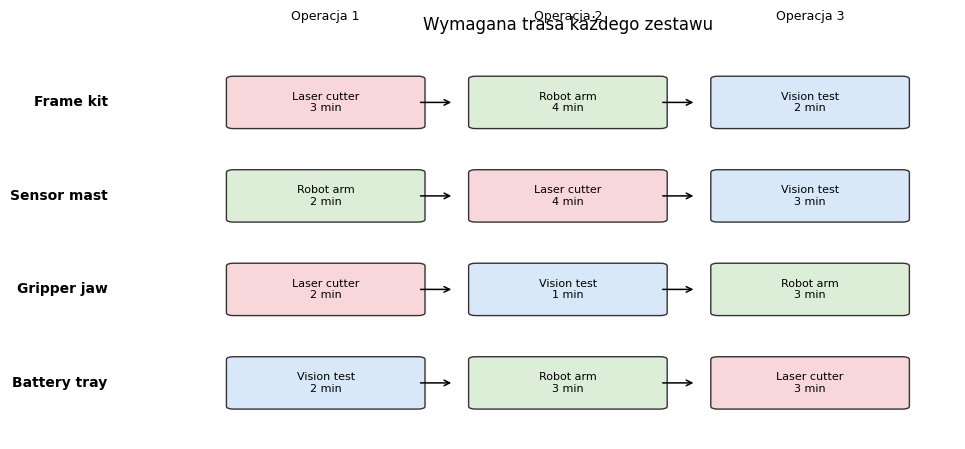

In [3]:
# Pokaż kolejność operacji prostokątami w kolorach stanowisk; to nie jest harmonogram czasowy.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


def plot_job_routes(jobs):
    """Rysuje wymaganą trasę operacji każdego zadania, bez harmonogramowania.

    jobs przypisuje nazwom zadań uporządkowane krotki
    (station, processing_time_in_minutes). Pozycja x prostokąta oznacza
    kolejność operacji, nie czas rozpoczęcia; kolor oznacza stanowisko.
    Korzysta z globalnych plt i FancyBboxPatch. Tworzy figurę i zwraca
    (fig, ax) do wyświetlenia lub modyfikacji. Nie wymaga solvera."""
    station_colors = {
        "Laser cutter": "#F8D7DA",
        "Robot arm": "#DDEED8",
        "Vision test": "#D8E8F8",
    }

    # Współrzędne rozdzielają zadania pionowo, a etapy trasy poziomo.
    job_names = list(jobs)
    max_operations = max(len(route) for route in jobs.values())
    fig, ax = plt.subplots(figsize=(10, 0.9 * len(job_names) + 1.5))
    ax.set_xlim(0.4, max_operations + 0.6)
    ax.set_ylim(-0.6, len(job_names) - 0.4)
    ax.axis("off")

    # Narysuj prostokąty trasy i połącz je z kolejnymi wymaganymi operacjami.
    for y, job in enumerate(reversed(job_names)):
        ax.text(0.1, y, job, ha="right", va="center", fontsize=10, weight="bold")
        route = jobs[job]
        for operation, (station, duration) in enumerate(route, start=1):
            x = operation
            box = FancyBboxPatch(
                (x - 0.38, y - 0.25),
                0.76,
                0.5,
                boxstyle="round,pad=0.03",
                linewidth=1,
                edgecolor="#333333",
                facecolor=station_colors.get(station, "#EFEFEF"),
            )
            ax.add_patch(box)
            ax.text(x, y, f"{station}\n{duration} min", ha="center", va="center", fontsize=8)
            if operation < len(route):
                ax.annotate("", xy=(x + 0.53, y), xytext=(x + 0.38, y), arrowprops={"arrowstyle": "->", "lw": 1.1})

    for operation in range(1, max_operations + 1):
        ax.text(operation, len(job_names) - 0.15, f"Operacja {operation}", ha="center", va="bottom", fontsize=9)

    ax.set_title('Wymagana trasa każdego zestawu', pad=12)
    return fig, ax


plot_job_routes(jobs);

## Rozgrzewka: dwa zadania i dwa stanowiska

Najpierw rozwiąż ręcznie mały przykład.

- Zadanie A (`Job A`): `Station 1` przez 5 minut, następnie `Station 2` przez 6 minut.
- Zadanie B (`Job B`): `Station 2` przez 4 minuty, następnie `Station 1` przez 7 minut.

`Station 1` i `Station 2` oznaczają stanowiska 1 i 2; angielskie nazwy są kluczami danych.

Pytania:

1. Czy obie pierwsze operacje mogą rozpocząć się w chwili 0?
2. Co musi się wydarzyć, zanim zadanie A skorzysta ze stanowiska 2?
3. Co musi się wydarzyć, zanim zadanie B skorzysta ze stanowiska 1?
4. Narysuj ręcznie harmonogram. Optymalny czas zakończenia wszystkich zadań wynosi **12 minut**.

Na każdym stanowisku albo A poprzedza B, albo B poprzedza A. Tę decyzję „albo–albo” reprezentuje zmienna binarna.

In [4]:
# Zapisz przykład dwóch zadań i przekształć go w czytelną tabelę operacji.
warmup_jobs = {
    "Job A": [
        ("Station 1", 5),
        ("Station 2", 6),
    ],
    "Job B": [
        ("Station 2", 4),
        ("Station 1", 7),
    ],
}

warmup_rows = []
for job, route in warmup_jobs.items():
    for operation, (station, duration) in enumerate(route, start=1):
        warmup_rows.append({
            "job": job,
            "operation": operation,
            "station": station,
            "duration": duration,
        })

pd.DataFrame(warmup_rows)


,job,operation,station,duration
0,Job A,1,Station 1,5
1,Job A,2,Station 2,6
2,Job B,1,Station 2,4
3,Job B,2,Station 1,7


## Idea modelu

Dla każdej operacji tworzymy zmienną czasu rozpoczęcia:

$$s_{j,k} \ge 0$$

gdzie $j$ oznacza zadanie, a $k$ — numer operacji w tym zadaniu.

Model zawiera trzy grupy ograniczeń.

### 1. Kolejność operacji w zadaniu

Jeśli operacja 2 następuje po operacji 1, nie może rozpocząć się przed zakończeniem operacji 1:

$$s_{j,2} \ge s_{j,1} + p_{j,1}$$

### 2. Brak nakładania się operacji na jednym stanowisku

Jeśli operacje `a` i `b` wymagają tego samego stanowiska, jedna musi poprzedzać drugą. Wprowadzamy zmienną binarną $y_{a,b}$.

Dla $y_{a,b}=1$ operacja `a` poprzedza `b`; dla $y_{a,b}=0$ operacja `b` poprzedza `a`.

Dwa ograniczenia typu duże M (Big-M) mają postać:

$$s_b \ge s_a + p_a - M(1-y_{a,b})$$

$$s_a \ge s_b + p_b - My_{a,b}$$

Składnik z dużym M działa jak przełącznik. Po wybraniu kolejności jedno ograniczenie jest aktywne i zapobiega nakładaniu się operacji. Drugie zawiera duże odejmowanie, więc przestaje ograniczać harmonogram. $M$ musi być dostatecznie duże, aby wyłączyć nieaktywny warunek, lecz nie przesadnie duże. Tutaj przyjmujemy sumę czasów wszystkich operacji: to bezpieczny horyzont tego podstawowego modelu, ponieważ nawet wykonywanie operacji pojedynczo zakończyłoby się do tej chwili. Jeśli dodasz czasy dostępności zadań, okna konserwacji lub inne warunki wymuszające przestoje, zwiększ horyzont, aby duże M nadal było wystarczające.

### 3. Czas zakończenia wszystkich zadań

Czas zakończenia wszystkich zadań musi być nie mniejszy od czasu zakończenia ostatniej operacji każdego zadania:

$$C_{max} \ge s_{j,last} + p_{j,last}$$

Funkcja celu:

$$\min C_{max}$$

### Solver wielokrotnego użytku: słownik tras → tabela harmonogramu

`solve_jobshop(jobs, msg=False, horizon=None)` przyjmuje uporządkowany słownik tras, tworzy zmienne czasu i kolejności, dodaje ograniczenia tras, rozłączności oraz czasu zakończenia, rozwiązuje model i zapisuje optymalne czasy w DataFrame. Zwraca `(makespan, schedule, model)`, więc rozgrzewka i główny przykład korzystają z tej samej implementacji. Klucze `(job, operation_index)` identyfikują operacje: wewnętrzne indeksy zaczynają się od zera, a numery w tabeli — od jednego. Pomocnicze funkcje `_safe_name` i `_operation_name` tworzą czytelne nazwy solvera z etykiet i krotek. Gdy solver nie znajdzie optimum, funkcja zgłasza błąd przed odczytaniem harmonogramu.

In [5]:
from itertools import combinations
import re
import pulp

def _safe_name(text):
    return re.sub(r"[^A-Za-z0-9_]+", "_", str(text)).strip("_")

def _operation_name(operation):
    job, index = operation
    return f"{_safe_name(job)}_op{index + 1}"

def solve_jobshop(jobs, msg=False, horizon=None, maintenance=None, deadline=None, tardiness_weight=0):
    model = pulp.LpProblem("Robot_Cell_Job_Shop", pulp.LpMinimize)

    operations = [
        (job, operation_index)
        for job, route in jobs.items()
        for operation_index in range(len(route))
    ]
    station_of = {
        (job, operation_index): jobs[job][operation_index][0]
        for job, operation_index in operations
    }
    duration = {
        (job, operation_index): jobs[job][operation_index][1]
        for job, operation_index in operations
    }
    if horizon is None:
        horizon = sum(duration[operation] for operation in operations)
        if maintenance is not None:
            horizon += maintenance[2]

    # Tworzymy zmienne za pomocą bezpiecznych argumentów nazwanych (keyword arguments),
    # przekazując stałe PuLP jako typy zmiennych.
    start = {}
    for operation in operations:
        start[operation] = pulp.LpVariable(
            name=f"start__{_operation_name(operation)}",
            lowBound=0,
            cat=pulp.LpContinuous
        )

    cmax = pulp.LpVariable(name="Cmax", lowBound=0, cat=pulp.LpContinuous)

    if deadline is None:
        model += cmax, "minimize_makespan"
    else:
        deadline_job, due_time = deadline
        if deadline_job not in jobs:
            raise ValueError(f"Nieznane zadanie: {deadline_job}")
        tardiness = pulp.LpVariable(name=f"tardiness__{_safe_name(deadline_job)}", lowBound=0, cat=pulp.LpContinuous)
        model += cmax + tardiness_weight * tardiness, "minimize_makespan_and_tardiness"

    for job, route in jobs.items():
        for operation_index in range(len(route) - 1):
            current_operation = (job, operation_index)
            next_operation = (job, operation_index + 1)
            model += (
                start[next_operation] >= start[current_operation] + duration[current_operation],
                f"route__{_operation_name(current_operation)}__before__{_operation_name(next_operation)}",
            )

    stations = sorted({station for route in jobs.values() for station, _ in route})
    for station in stations:
        station_operations = [operation for operation in operations if station_of[operation] == station]
        for first_operation, second_operation in combinations(station_operations, 2):
            order = pulp.LpVariable(
                name=f"order__{_safe_name(station)}__{_operation_name(first_operation)}__before__{_operation_name(second_operation)}",
                lowBound=0,
                upBound=1,
                cat=pulp.LpBinary
            )
            model += (
                start[second_operation]
                >= start[first_operation] + duration[first_operation] - horizon * (1 - order),
                f"no_overlap__{_safe_name(station)}__{_operation_name(first_operation)}__before__{_operation_name(second_operation)}",
            )
            model += (
                start[first_operation]
                >= start[second_operation] + duration[second_operation] - horizon * order,
                f"no_overlap__{_safe_name(station)}__{_operation_name(second_operation)}__before__{_operation_name(first_operation)}",
            )

    if maintenance is not None:
        maintenance_station, maintenance_start, maintenance_end = maintenance
        if maintenance_end <= maintenance_start or maintenance_start < 0:
            raise ValueError("Niepoprawny przedzial konserwacji")
        if maintenance_station not in stations:
            raise ValueError(f"Nieznane stanowisko: {maintenance_station}")
        if horizon < maintenance_end + sum(duration.values()):
            raise ValueError("Horyzont jest za maly dla konserwacji")
        for operation in operations:
            if station_of[operation] != maintenance_station:
                continue
            before = pulp.LpVariable(
                name=f"before_maintenance__{_operation_name(operation)}",
                lowBound=0,
                upBound=1,
                cat=pulp.LpBinary
            )
            model += (
                start[operation] + duration[operation]
                <= maintenance_start + horizon * (1 - before),
                f"maintenance_before__{_operation_name(operation)}",
            )
            model += (
                start[operation] >= maintenance_end - horizon * before,
                f"maintenance_after__{_operation_name(operation)}",
            )

    if deadline is not None:
        last_operation = (deadline_job, len(jobs[deadline_job]) - 1)
        model += (
            tardiness >= start[last_operation] + duration[last_operation] - due_time,
            f"tardiness_after__{_safe_name(deadline_job)}",
        )

    for job, route in jobs.items():
        last_operation = (job, len(route) - 1)
        model += (
            cmax >= start[last_operation] + duration[last_operation],
            f"makespan_after__{_safe_name(job)}",
        )

    solver = pulp.PULP_CBC_CMD(msg=msg)
    model.solve(solver)

    status = pulp.LpStatus[model.status]
    if status != "Optimal":
        raise RuntimeError(
            f"Status solvera: {status}; oczekiwano Optimal. "
            'Sprawdź wykonalność tras i ograniczeń rozłączności.'
        )

    rows = []
    for job, route in jobs.items():
        for operation_index, (station, processing_time) in enumerate(route):
            operation = (job, operation_index)
            start_time = pulp.value(start[operation])
            if start_time is None:
                raise RuntimeError(
                    f"Brak czasu rozpoczęcia dla {job}, operacja {operation_index + 1}. "
                )
            rows.append({
                "job": job,
                "operation": operation_index + 1,
                "station": station,
                "start": start_time,
                "duration": processing_time,
                "finish": start_time + processing_time,
            })

    schedule = (
        pd.DataFrame(rows)
        .sort_values(["station", "start", "job"])
        .reset_index(drop=True)
    )
    return pulp.value(cmax), schedule, model

In [6]:
# Najpierw użyj solvera dla przykładu sprawdzonego ręcznie, potem dla pełnej komórki.
warmup_makespan, warmup_schedule, warmup_model = solve_jobshop(warmup_jobs)
print(f"Optymalny czas zakończenia wszystkich zadań rozgrzewki: {warmup_makespan:.0f} minut")
print('Oczekiwana wartość dla pierwotnych danych rozgrzewki: 12 minut')
warmup_schedule

Optymalny czas zakończenia wszystkich zadań rozgrzewki: 12 minut
Oczekiwana wartość dla pierwotnych danych rozgrzewki: 12 minut


,job,operation,station,start,duration,finish
0,Job A,1,Station 1,0.0,5,5.0
1,Job B,2,Station 1,5.0,7,12.0
2,Job B,1,Station 2,0.0,4,4.0
3,Job A,2,Station 2,5.0,6,11.0


In [9]:
# Rozwiąż główny przykład tą samą funkcją i obejrzyj harmonogram w minutach.
makespan, schedule, model = solve_jobshop(jobs)
print(f"Optymalny czas zakończenia wszystkich zadań komórki: {makespan:.0f} minut")
print('Oczekiwana wartość dla pierwotnych danych komórki: 13 minut')
schedule


Optymalny czas zakończenia wszystkich zadań komórki: 13 minut
Oczekiwana wartość dla pierwotnych danych komórki: 13 minut


,job,operation,station,start,duration,finish
0,Frame kit,1,Laser cutter,0.0,3,3.0
1,Sensor mast,2,Laser cutter,3.0,4,7.0
2,Gripper jaw,1,Laser cutter,7.0,2,9.0
3,Battery tray,3,Laser cutter,10.0,3,13.0
4,Sensor mast,1,Robot arm,0.0,2,2.0
5,Frame kit,2,Robot arm,3.0,4,7.0
6,Battery tray,2,Robot arm,7.0,3,10.0
7,Gripper jaw,3,Robot arm,10.0,3,13.0
8,Battery tray,1,Vision test,0.0,2,2.0
9,Frame kit,3,Vision test,7.0,2,9.0


## Sprawdź harmonogram przed narysowaniem wykresu

Wykres Gantta ułatwia oglądanie harmonogramu, ale najpierw automatycznie sprawdź reguły.

Poprawny harmonogram spełnia dwa warunki:

1. każde zadanie zachowuje kolejność swojej trasy,
2. operacje na tym samym stanowisku nie nakładają się w czasie.

`validate_schedule(jobs, schedule, tolerance=1e-7)` przyjmuje pierwotne trasy i tabelę harmonogramu. Indeksuje wiersze krotkami operacji, sprawdza kolejność, a następnie grupuje i sortuje operacje według stanowisk, aby porównać sąsiednie przedziały. Zwraca komunikat potwierdzający poprawność albo zgłasza błąd asercji przy naruszeniu reguły. Uruchamiaj ją po każdym rozwiązaniu scenariusza; tolerancja to niewielka liczba minut uwzględniająca błędy numeryczne solvera.

In [10]:
# Sprawdź reguły harmonogramu niezależnie od modelu optymalizacji.
def validate_schedule(jobs, schedule, tolerance=1e-7):
    """Sprawdza kolejność tras i rozłączność operacji w rozwiązanym harmonogramie.

    jobs to uporządkowany słownik tras użyty w modelu. schedule jest tabelą
    z solve_jobshop, z numerami operacji od 1 i start/finish w minutach.
    tolerance=1e-7 minut pomija szum numeryczny. Zakłada obecność wszystkich
    operacji modelu w tabeli. Zwraca "Harmonogram jest poprawny.", jeśli
    oba warunki są spełnione; w przeciwnym razie zgłasza AssertionError.
    Nie uruchamia solvera ani niczego nie wyświetla. Wywołuj po każdym
    ponownym rozwiązaniu, przed rysowaniem wykresu."""
    # Indeksuj wiersze krotkami, aby łatwo porównać kolejne operacje trasy.
    indexed = {
        (row.job, int(row.operation) - 1): row
        for row in schedule.itertuples(index=False)
    }

    # Następnik nie może rozpocząć się przed zakończeniem poprzednika.
    for job, route in jobs.items():
        for operation_index in range(len(route) - 1):
            current_operation = indexed[(job, operation_index)]
            next_operation = indexed[(job, operation_index + 1)]
            if next_operation.start + tolerance < current_operation.finish:
                raise AssertionError(
                    f"Naruszenie trasy zadania {job}: operacja {operation_index + 2} "
                    f"zaczyna się przed zakończeniem operacji {operation_index + 1}."
                )

    # Posortuj operacje stanowiska w czasie i sprawdź nakładanie sąsiednich przedziałów.
    for station, station_schedule in schedule.groupby("station"):
        ordered = station_schedule.sort_values("start")
        previous_operation = None
        for operation in ordered.itertuples(index=False):
            if (
                previous_operation is not None
                and operation.start + tolerance < previous_operation.finish
            ):
                raise AssertionError(
                    f"Nakładanie operacji na {station}: {previous_operation.job} i {operation.job}."
                )
            previous_operation = operation

    return 'Harmonogram jest poprawny.'


validate_schedule(warmup_jobs, warmup_schedule), validate_schedule(jobs, schedule)

('Harmonogram jest poprawny.', 'Harmonogram jest poprawny.')

## Funkcja wykresu Gantta: tabela → oś czasu stanowisk

`plot_gantt(schedule, title=...)` przyjmuje sprawdzoną tabelę harmonogramu i zwraca `(fig, ax)`. Przypisuje stanowiskom wiersze, a zadaniom kolory; rysuje operacje od ich czasów rozpoczęcia, z szerokością równą czasowi trwania, a następnie dodaje etykiety minut, stanowisk i legendę zadań. Po zmianie tras lub czasów użyj jej ponownie. Funkcja pokazuje podane wartości — nie rozwiązuje modelu ani nie sprawdza harmonogramu.

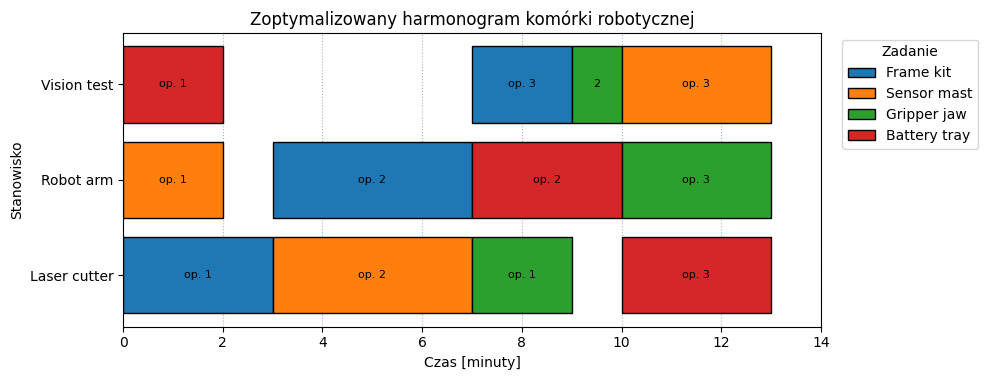

In [11]:
# Narysuj sprawdzony harmonogram jako paski na osiach czasu stanowisk.
import matplotlib.pyplot as plt


def plot_gantt(schedule, title='Zoptymalizowany harmonogram komórki robotycznej'):
    """Tworzy wykres Gantta stanowisko–czas z tabeli rozwiązanego harmonogramu.

    schedule ma kolumny job, operation, station, start, duration, finish;
    wszystkie czasy są w minutach. title domyślnie opisuje zoptymalizowany
    harmonogram komórki. Korzysta z globalnego plt; kolor identyfikuje
    zadanie, a wiersz — stanowisko. Zwraca (fig, ax) do wyświetlenia lub
    modyfikacji. Rysuje podane dane bez rozwiązywania modelu i sprawdzania
    reguł; najpierw wywołaj validate_schedule."""
    # Przypisz stanowiskom pozycje y, a zadaniom spójne kolory.
    stations = list(schedule["station"].drop_duplicates())
    jobs_in_schedule = list(schedule["job"].drop_duplicates())
    y_position = {station: index for index, station in enumerate(stations)}
    color_map = {
        job: plt.get_cmap("tab10")(index % 10)
        for index, job in enumerate(jobs_in_schedule)
    }

    fig_height = max(3.5, 0.8 * len(stations) + 1.5)
    fig, ax = plt.subplots(figsize=(10, fig_height))
    labelled_jobs = set()

    # Wiersze tabeli wyznaczają początek i szerokość pasków oraz jedną etykietę legendy na zadanie.
    for row in schedule.itertuples(index=False):
        y = y_position[row.station]
        label = row.job if row.job not in labelled_jobs else None
        labelled_jobs.add(row.job)

        ax.barh(
            y,
            row.duration,
            left=row.start,
            color=color_map[row.job],
            edgecolor="black",
            label=label,
        )
        operation_label = f"op. {int(row.operation)}" if row.duration >= 1.8 else str(int(row.operation))
        ax.text(
            row.start + row.duration / 2,
            y,
            operation_label,
            ha="center",
            va="center",
            fontsize=8,
        )

    # Podpisz minuty i stanowiska oraz pozostaw miejsce na legendę zadań.
    ax.set_yticks(list(y_position.values()))
    ax.set_yticklabels(list(y_position.keys()))
    ax.set_xlabel('Czas [minuty]')
    ax.set_ylabel('Stanowisko')
    ax.set_title(title)
    ax.set_xlim(0, schedule["finish"].max() + 1)
    ax.grid(axis="x", linestyle=":")
    ax.set_axisbelow(True)
    ax.legend(title='Zadanie', bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    return fig, ax


plot_gantt(schedule);

## Zadania do wykonania

### Zadanie 1: wskaż elementy optymalizacji

Uzupełnij:

- Zadania: `__________`
- Stanowiska: `__________`
- Zmienne decyzyjne: `__________`
- Funkcja celu: `__________`
- Dwie główne rodziny ograniczeń: `__________`

### Zadanie 2: zmień dane

Ramię robota otrzymuje szybszy chwytak. Każda operacja **Robot arm** trwa o 1 minutę krócej, ale nie mniej niż 1 minutę. Rozwiąż model ponownie. O ile poprawia się czas zakończenia wszystkich zadań?

### Zadanie 3: analiza wąskich gardeł

Na podstawie wykresu Gantta odpowiedz:

- Które stanowisko pracuje najdłużej?
- Które stanowisko ma najwięcej czasu bezczynności?
- Które zadanie kończy się jako ostatnie?
- Czy ostatnie zadanie musi być wąskim gardłem? Wyjaśnij.

### Zadanie 4: dodaj okno konserwacji

Stanowisko kontroli wizyjnej jest niedostępne od chwili 4 do chwili 6. Rozszerz model tak, aby żadna operacja na tym stanowisku nie nakładała się na ten przedział.

Wskazówka: to kolejna decyzja „albo–albo”. Każda operacja kontroli wizyjnej musi zakończyć się przed minutą 4 albo rozpocząć po minucie 6.

### Wyzwanie: terminy realizacji

Załóż, że gościom najbardziej zależy na `Frame kit`, który ma być gotowy w minucie 10. Dodaj zmienną spóźnienia.

Czas zakończenia $C_j$ określa, kiedy zadanie $j$ jest gotowe. Termin $d_j$ określa, kiedy powinno być gotowe. Spóźnienie to opóźnienie względem terminu:

$$T_j \ge C_j - d_j$$

Dodaj również $T_j \ge 0$, ponieważ wcześniejsze zakończenie ma dawać zerowe spóźnienie, a nie ujemną karę. Jeśli `Frame kit` kończy się w minucie 13, a termin wynosi 10, to $T_j=3$.

Następnie rozwiąż jeden z wariantów:

- najpierw minimalizuj czas zakończenia wszystkich zadań, a następnie spóźnienie,
- albo minimalizuj `makespan + 0.5 * total_tardiness`.

## Rozwiązania zadań

Poniżej znajdują się odpowiedzi i kod do kolejnych zadań.


### Rozgrzewka: odpowiedzi

1. Tak, ponieważ na początku zadania A i B korzystają z innych stanowisk.
2. Zadanie A musi najpierw skończyć pracę na stanowisku 1. Stanowisko 2 musi też być wolne.
3. Zadanie B musi najpierw skończyć pracę na stanowisku 2 i poczekać na zwolnienie stanowiska 1.
4. Przykładowy plan: A pracuje na stanowisku 1 od 0 do 5 minuty, a na stanowisku 2 od 5 do 11. B pracuje na stanowisku 2 od 0 do 4 minuty, a na stanowisku 1 od 5 do 12. Całość trwa **12 minut**.


### Zadanie 1: elementy optymalizacji

- **Zadania:** `Frame kit`, `Sensor mast`, `Gripper jaw`, `Battery tray`.
- **Stanowiska:** `Laser cutter`, `Robot arm`, `Vision test`.
- **Zmienne decyzyjne:** czas rozpoczęcia każdej operacji, kolejność operacji na tym samym stanowisku i czas zakończenia całości (`Cmax`).
- **Funkcja celu:** zakończyć wszystkie zadania jak najszybciej, czyli zminimalizować `Cmax`.
- **Dwa główne ograniczenia:** operacje w każdym zadaniu muszą iść po kolei, a jedno stanowisko nie może wykonywać dwóch operacji naraz.


### Zadanie 2: szybsze ramię robota

Skracam każdą operację na `Robot arm` o 1 minutę, ale żadna nie może trwać krócej niż 1 minutę. Pozostałe dane zostają bez zmian.


Harmonogram jest poprawny.
Oryginalny makespan: 13 min
Makespan po przyspieszeniu: 12 min
Poprawa: 1 min


,job,operation,station,start,duration,finish
0,Frame kit,1,Laser cutter,0.0,3,3.0
1,Gripper jaw,1,Laser cutter,3.0,2,5.0
2,Sensor mast,2,Laser cutter,5.0,4,9.0
3,Battery tray,3,Laser cutter,9.0,3,12.0
4,Sensor mast,1,Robot arm,0.0,1,1.0
5,Battery tray,2,Robot arm,2.0,2,4.0
6,Frame kit,2,Robot arm,4.0,3,7.0
7,Gripper jaw,3,Robot arm,7.0,2,9.0
8,Battery tray,1,Vision test,0.0,2,2.0
9,Gripper jaw,2,Vision test,6.0,1,7.0


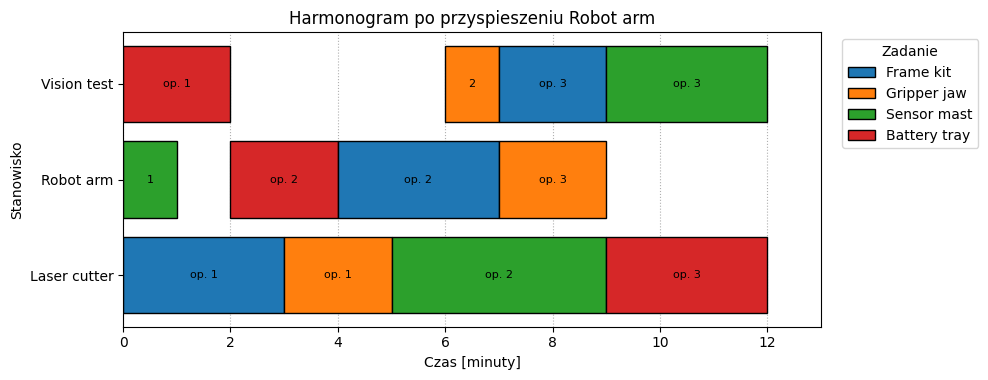

In [12]:
# Utworz osobny wariant danych z krotszym czasem pracy robota.
fast_jobs = {
    job: [
        (station, max(1, duration - 1) if station == "Robot arm" else duration)
        for station, duration in route
    ]
    for job, route in jobs.items()
}

fast_makespan, fast_schedule, fast_model = solve_jobshop(fast_jobs)
print(validate_schedule(fast_jobs, fast_schedule))
print(f"Oryginalny makespan: {makespan:.0f} min")
print(f"Makespan po przyspieszeniu: {fast_makespan:.0f} min")
print(f"Poprawa: {makespan - fast_makespan:.0f} min")
display(fast_schedule)
plot_gantt(fast_schedule, title="Harmonogram po przyspieszeniu Robot arm");

Przed zmianą całość trwała 13 minut, a po zmianie 12 minut. Czas skrócił się o 1 minutę, mimo że łączny czas pracy robota zmniejszył się o 4 minuty.


### Zadanie 3: analiza wąskich gardeł

1. Najdłużej pracują `Laser cutter` i `Robot arm`, po 12 minut.
2. Najwięcej czasu bezczynności ma `Vision test` (5 minut). Pozostałe stanowiska mają po 1 minucie przerwy.
3. W otrzymanym harmonogramie `Battery tray`, `Gripper jaw` i `Sensor mast` kończą się w 13. minucie. Przy innym optymalnym harmonogramie kolejność zakończenia może się zmienić.
4. Nie, ostatnie zadanie może po prostu czekać na wolne stanowisko. Wąskie gardło to zasób, który ogranicza tempo pracy całego układu.


In [13]:
# Policz czasy wykorzystania i bezczynnosci stanowisk dla oryginalnego wariantu.
station_summary = (
    schedule.groupby("station", as_index=False)["duration"]
    .sum()
    .rename(columns={"duration": "working_minutes"})
)
station_summary["idle_minutes"] = makespan - station_summary["working_minutes"]
station_summary["utilization_percent"] = (
    100 * station_summary["working_minutes"] / makespan
).round(2)
job_finishes = schedule.groupby("job")["finish"].max()
last_jobs = job_finishes[job_finishes >= job_finishes.max() - 1e-7].index.tolist()
print("Stanowiska pracujace najdluzej:", station_summary.loc[
    station_summary["working_minutes"] == station_summary["working_minutes"].max(), "station"
].tolist())
print("Stanowisko z najwieksza bezczynnoscia:", station_summary.loc[
    station_summary["idle_minutes"] == station_summary["idle_minutes"].max(), "station"
].tolist())
print("Ostatnie zadanie lub zadania:", ", ".join(last_jobs))
display(station_summary)
display(job_finishes.rename("finish_minute").to_frame())

Stanowiska pracujace najdluzej: ['Laser cutter', 'Robot arm']
Stanowisko z najwieksza bezczynnoscia: ['Vision test']
Ostatnie zadanie lub zadania: Battery tray, Gripper jaw, Sensor mast


,station,working_minutes,idle_minutes,utilization_percent
0,Laser cutter,12,1.0,92.31
1,Robot arm,12,1.0,92.31
2,Vision test,8,5.0,61.54


,finish_minute
job,
Battery tray,13.0
Frame kit,9.0
Gripper jaw,13.0
Sensor mast,13.0


### Zadanie 4: konserwacja stanowiska `Vision test` (4–6 min)

Dodaję do modelu przerwę na konserwację od 4. do 6. minuty. Każda operacja na `Vision test` musi się skończyć najpóźniej w 4. minucie albo zacząć od 6. minuty. Dzięki temu w czasie konserwacji stanowisko nie pracuje.


Harmonogram jest poprawny.
Makespan bez konserwacji: 13 min
Makespan z konserwacja: 13 min
Zmiana: 0 min


,job,operation,station,start,duration,finish
0,Frame kit,1,Laser cutter,0.0,3,3.0
1,Gripper jaw,1,Laser cutter,3.0,2,5.0
2,Sensor mast,2,Laser cutter,5.0,4,9.0
3,Battery tray,3,Laser cutter,10.0,3,13.0
4,Sensor mast,1,Robot arm,0.0,2,2.0
5,Frame kit,2,Robot arm,3.0,4,7.0
6,Battery tray,2,Robot arm,7.0,3,10.0
7,Gripper jaw,3,Robot arm,10.0,3,13.0
8,Battery tray,1,Vision test,0.0,2,2.0
9,Gripper jaw,2,Vision test,6.0,1,7.0


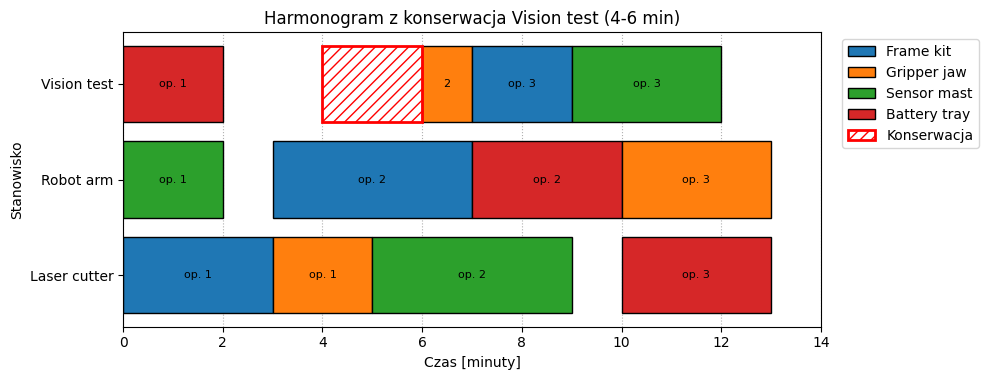

In [14]:
# Rozwiaz oryginalne zadania z niedostepnoscia stanowiska Vision test.
maintenance = ("Vision test", 4, 6)
maintenance_makespan, maintenance_schedule, maintenance_model = solve_jobshop(
    jobs, maintenance=maintenance
)
print(validate_schedule(jobs, maintenance_schedule))
vision_operations = maintenance_schedule[
    maintenance_schedule["station"] == "Vision test"
]
assert all(
    row.finish <= 4 + 1e-7 or row.start >= 6 - 1e-7
    for row in vision_operations.itertuples(index=False)
)
print(f"Makespan bez konserwacji: {makespan:.0f} min")
print(f"Makespan z konserwacja: {maintenance_makespan:.0f} min")
print(f"Zmiana: {maintenance_makespan - makespan:.0f} min")
display(maintenance_schedule)
fig, ax = plot_gantt(maintenance_schedule, title="Harmonogram z konserwacja Vision test (4-6 min)")
vision_y = list(maintenance_schedule["station"].drop_duplicates()).index("Vision test")
ax.barh(vision_y, 2, left=4, facecolor="none", edgecolor="red", hatch="///", linewidth=2, label="Konserwacja")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left");

Po dodaniu konserwacji wszystkie zadania nadal kończą się w 13. minucie. Wystarczy zmienić kolejność i czasy rozpoczęcia niektórych operacji.


### Wyzwanie: termin wykonania `Frame kit`

Ustawiam termin ukończenia `Frame kit` na 10. minutę. Jeśli zadanie skończy się później, liczę spóźnienie. W funkcji celu minimalizuję `Cmax + 0.5 * T`, czyli czas zakończenia wszystkich zadań z dodatkową karą za spóźnienie.


Harmonogram jest poprawny.
Makespan: 13 min
Frame kit konczy sie w: 9 min
Spoznienie Frame kit: 0 min
Wartosc funkcji celu: 13


,job,operation,station,start,duration,finish
0,Frame kit,1,Laser cutter,0.0,3,3.0
1,Gripper jaw,1,Laser cutter,3.0,2,5.0
2,Sensor mast,2,Laser cutter,5.0,4,9.0
3,Battery tray,3,Laser cutter,10.0,3,13.0
4,Sensor mast,1,Robot arm,0.0,2,2.0
5,Frame kit,2,Robot arm,3.0,4,7.0
6,Battery tray,2,Robot arm,7.0,3,10.0
7,Gripper jaw,3,Robot arm,10.0,3,13.0
8,Battery tray,1,Vision test,0.0,2,2.0
9,Gripper jaw,2,Vision test,6.0,1,7.0


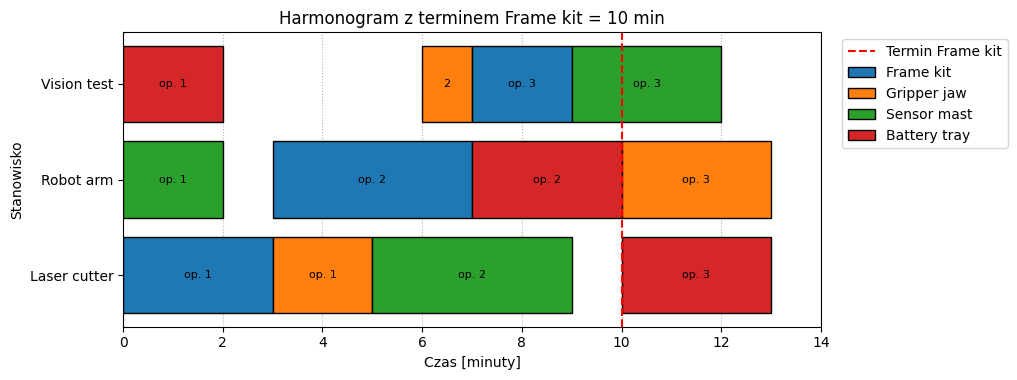

In [15]:
# Uwzglednij termin oddania Frame kit i kare za spoznienie.
deadline = ("Frame kit", 10)
deadline_makespan, deadline_schedule, deadline_model = solve_jobshop(
    jobs, deadline=deadline, tardiness_weight=0.5
)
print(validate_schedule(jobs, deadline_schedule))
frame_finish = deadline_schedule.loc[
    deadline_schedule["job"] == "Frame kit", "finish"
].max()
frame_tardiness = max(0, frame_finish - 10)
objective_value = deadline_makespan + 0.5 * frame_tardiness
print(f"Makespan: {deadline_makespan:.0f} min")
print(f"Frame kit konczy sie w: {frame_finish:g} min")
print(f"Spoznienie Frame kit: {frame_tardiness:g} min")
print(f"Wartosc funkcji celu: {objective_value:g}")
display(deadline_schedule)
fig, ax = plot_gantt(deadline_schedule, title="Harmonogram z terminem Frame kit = 10 min")
ax.axvline(10, color="red", linestyle="--", label="Termin Frame kit")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left");

W otrzymanym harmonogramie `Frame kit` kończy się w 9. minucie, czyli minutę przed terminem. Spóźnienie wynosi 0, a czas całego harmonogramu nadal wynosi 13 minut.


### Podsumowanie

| Wariant | Czas zakończenia wszystkich zadań |
|---|---:|
| Bez zmian | 13 min |
| Szybsze ramię robota | 12 min |
| Konserwacja `Vision test` | 13 min |
| Termin `Frame kit` w 10. minucie | 13 min (bez spóźnienia) |

Tylko przyspieszenie ramienia skróciło czas realizacji całego harmonogramu. Konserwacja i dodatkowy termin nie wydłużyły tego czasu.


### Sprawdzenie wyników

Poniższa komórka sprawdza, czy obliczone czasy i harmonogramy są poprawne.


In [ ]:
# Sprawdz wyniki wszystkich wariantow harmonogramowania.
assert abs(warmup_makespan - 12) < 1e-6
assert abs(makespan - 13) < 1e-6
assert abs(fast_makespan - 12) < 1e-6
assert abs(maintenance_makespan - 13) < 1e-6
assert abs(deadline_makespan - 13) < 1e-6

for dane, harmonogram in [
    (warmup_jobs, warmup_schedule),
    (jobs, schedule),
    (fast_jobs, fast_schedule),
    (jobs, maintenance_schedule),
    (jobs, deadline_schedule),
]:
    assert validate_schedule(dane, harmonogram) == "Harmonogram jest poprawny."

assert all(
    row.finish <= 4 + 1e-7 or row.start >= 6 - 1e-7
    for row in maintenance_schedule.loc[
        maintenance_schedule["station"] == "Vision test"
    ].itertuples(index=False)
)
assert frame_finish <= 10 + 1e-7
assert abs(frame_tardiness) < 1e-7

print("Wszystkie kontrole zakonczone pomyslnie.")